# Recovering a pose: how to judge an alignment

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/08_recovering_a_pose.ipynb)

A field model compares molecules in one frame, so a new molecule has to be put into that frame
before it can be predicted. This is called finding its **pose**. The first notebook used a series
that came aligned. A new molecule never does.

How should a method that finds poses be judged? Not by q2. Realigning changes the geometry that q2
is computed on, so a method can be rewarded for making the data look like the model. The judge has
to come from outside the model. The FEP benchmark sets in `examples/openff` supply it: every ligand
of a set was crystallised in the same protein, in one frame, so the pose a method should find is
known. The protocol of `cmfqsar/poses.py` uses this:

1. fit a model on the training molecules in their crystal poses;
2. destroy the poses of the held-out molecules (a random place near the site and a random
   orientation);
3. let each method recover them, without ever seeing a held-out activity;
4. report how near the crystal pose it came (the RMSD, in Å) and what the model then predicts.

Two fixed references bound every method: the crystal poses (the ceiling) and the destroyed poses
(the floor). The notebook asks three questions.

1. How well do the methods recover a pose when the conformation is known?
2. How well when the conformation has to be generated too, as for a real new molecule?
3. Is the recovered pose worth anything for the prediction, against a model that needs no pose?
   This reference is new in this notebook.

Running time: about one minute.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## One set, and the protocol run here

`load` reads the ligands of one set with their crystal poses and their measured affinity
(pAffinity). `split` holds out 30 % of them at random, and `judge` runs the protocol for the methods
it is given:

- **scrambled**: the destroyed poses, left as they are (the floor);
- **mcs**: superposition on the maximum common substructure with the nearest training molecule;
- **fieldgraph**: superposition by matching points of the fields, which needs no common
  substructure;
- **fieldgraph+variance**: the same, then a search that moves the molecule to where the model is
  most sure of its prediction (the smallest posterior variance).

Here the held-out molecules keep their crystal conformations, so only the pose is unknown. The
cell runs the protocol on four of the sixteen sets, with the settings of the stored runs.

In [2]:
import json
import os
import sys

os.environ["CMF_KERNEL_CACHE"] = "0"
sys.path.insert(0, "benchmarks")

import matplotlib.pyplot as plt
import numpy as np
from rdkit import RDLogger

RDLogger.DisableLog("rdApp.*")
import run_poses as P                     # the sets, splits and protocol of items C1 and C2
from cmfqsar.fields import FieldSet
from cmfqsar.poses import judge

fieldset = FieldSet.create(physchem=P.FIELDS, alpha=P.ALPHA, charge_model="gasteiger", param_scheme="rdkit")
methods = ("scrambled", "mcs", "fieldgraph", "fieldgraph+variance")
print("%-9s %4s %5s | %s" % ("set", "n", "held", "median RMSD to the crystal pose (A), then R2pred, for: crystal, " + ", ".join(methods)))
live = {}
for name in P.DEFAULT_SETS:
    mols, names, y = P.load(name)
    tr, te = P.split(len(mols))
    scores = judge(mols, names, y, tr, te, fieldset, methods=methods, lam=P.LAM, seed=0, restarts=2,
                   max_rotation_deg=30.0, reconform=False, conformers=0)
    live[name] = {k: v.row() for k, v in scores.items()}
    row = live[name]
    print("%-9s %4d %5d | " % (name, len(mols), len(te))
          + "  ".join("%5.2f" % row[k]["median_rmsd"] for k in ("crystal",) + methods)
          + "   R2pred " + " ".join("%+.2f" % row[k]["r2_pred"] for k in ("crystal",) + methods))

set          n  held | median RMSD to the crystal pose (A), then R2pred, for: crystal, scrambled, mcs, fieldgraph, fieldgraph+variance


jnk1        21     6 |  0.00   5.35   0.36   0.41   0.10   R2pred +0.62 -0.13 +0.58 +0.61 +0.62


thrombin    22     7 |  0.00   4.49   0.04   0.40   0.10   R2pred +0.40 -1.86 +0.40 +0.35 +0.44


p38         29     9 |  0.00   5.03   0.62   0.77   0.09   R2pred +0.11 -0.65 -0.00 -0.01 +0.10


mcl1        25     8 |  0.00   5.03   0.21   0.35   0.17   R2pred +0.54 -0.49 +0.30 -0.13 +0.39


The destroyed poses are 4.5 to 5.4 Å from the crystal pose, and the model predicts badly in them
(R2pred down to -1.86). Superposition on the common substructure brings the median back to 0.04
to 0.62 Å. The field points, with no substructure at all, reach 0.35 to 0.77 Å. Followed by the
search for the smallest posterior variance they reach 0.09 to 0.17 Å, and the model's prediction
in those poses is close to its prediction in the crystal poses on all four sets. When the
conformation is known, finding the pose is nearly solved.

## The sixteen sets, from the stored runs

`run_poses.py` runs the protocol on all sixteen sets. The first table reads the runs in which the
held-out molecules keep their crystal conformations. The second reads the runs in which their
conformations are **regenerated** from the structure formula, as for a real new molecule, with five
starting conformations, and in which the flexible search may also turn the rotatable bonds
(`flex`). The **conformer limit** is the RMSD that the best possible rigid placement of the starting
conformation would still leave: no pose search can go below it.

In [3]:
def summary(suffix, methods):
    rows = [json.load(open(os.path.join(P.RESULTS, s + suffix))) for s in P.SETS]
    print("%-22s %13s %11s %8s %16s" % ("method", "median RMSD", "within 2 A", "R2pred", "conformer limit"))
    for m in ("crystal",) + methods:
        got = [r["methods"][m] for r in rows if m in r["methods"]]
        print("%-22s %11.2f A %10.0f%% %+8.3f %14.2f A" % (m, np.mean([g["median_rmsd"] for g in got]),
              100 * np.mean([g["within_2A"] for g in got]), np.mean([g["r2_pred"] for g in got]),
              np.mean([g.get("conformer_limit", 0.0) for g in got])))
    return rows


print("crystal conformations, the pose destroyed (16 sets):")
rows_fg = summary("_fg.json", ("scrambled", "mcs", "field", "fieldgraph", "fieldgraph+field", "fieldgraph+variance"))
print()
print("regenerated conformations, five starting conformations (16 sets):")
rows_flex = summary("_flex_c5.json", ("scrambled", "mcs", "mcs+variance", "flex", "mcs+flex"))

crystal conformations, the pose destroyed (16 sets):
method                   median RMSD  within 2 A   R2pred  conformer limit
crystal                       0.00 A        100%   +0.334           0.00 A
scrambled                     5.29 A          0%   -0.683           0.00 A
mcs                           0.25 A         98%   +0.329           0.00 A
field                         0.48 A         97%   +0.293           0.00 A
fieldgraph                    0.67 A         94%   +0.206           0.00 A
fieldgraph+field              0.57 A         93%   +0.273           0.00 A
fieldgraph+variance           0.12 A         96%   +0.299           0.00 A

regenerated conformations, five starting conformations (16 sets):
method                   median RMSD  within 2 A   R2pred  conformer limit
crystal                       0.00 A        100%   +0.334           0.00 A
scrambled                     6.12 A          1%   -0.696           1.73 A
mcs                           1.94 A         54%   -0.3

The picture puts the two numbers of every method side by side, for the crystal conformations
over the sixteen sets: how far the recovered pose is from the crystal pose, and how well the model
predicts in it.

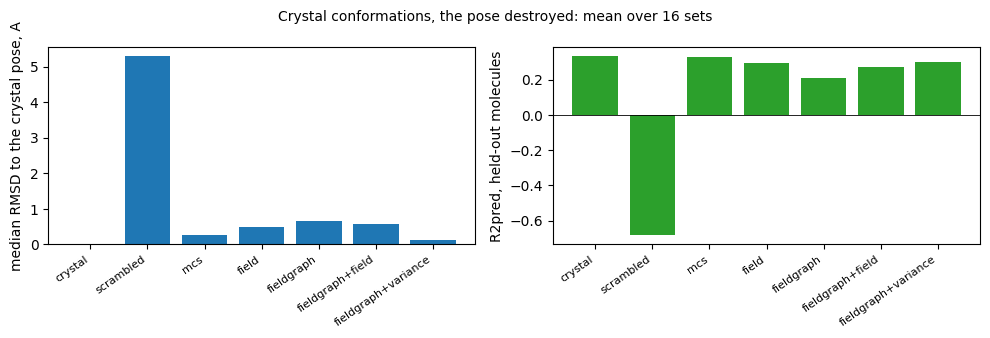

In [4]:
methods_fg = ("crystal", "scrambled", "mcs", "field", "fieldgraph", "fieldgraph+field", "fieldgraph+variance")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
rmsd = [np.mean([r["methods"][m]["median_rmsd"] for r in rows_fg if m in r["methods"]]) for m in methods_fg]
r2p = [np.mean([r["methods"][m]["r2_pred"] for r in rows_fg if m in r["methods"]]) for m in methods_fg]
axes[0].bar(range(len(methods_fg)), rmsd, color="tab:blue")
axes[0].set_ylabel("median RMSD to the crystal pose, A")
axes[1].bar(range(len(methods_fg)), r2p, color="tab:green")
axes[1].axhline(0, color="black", lw=0.6)
axes[1].set_ylabel("R2pred, held-out molecules")
for ax in axes:
    ax.set_xticks(range(len(methods_fg)))
    ax.set_xticklabels(methods_fg, rotation=35, ha="right", fontsize=8)
fig.suptitle("Crystal conformations, the pose destroyed: mean over 16 sets", fontsize=10)
plt.tight_layout()
plt.show()

With crystal conformations the sixteen sets agree with the four above. The substructure gives a
median of 0.25 Å and an R2pred of +0.329 against +0.334 in the crystal poses; the field points with
the variance search give 0.12 Å and +0.299, without needing a common substructure.

With regenerated conformations the problem is harder, and it is the real one. Substructure
superposition gives 1.94 Å and an R2pred of -0.391, worse than predicting the training mean. The
rigid variance search after it makes things worse (2.27 Å), because with a conformation fixed it
cannot reach the right shape. Freeing the rotatable bonds is what works: the flexible search after
the substructure, from five starting conformations, gives 0.86 Å, 88 % within 2 Å, and an R2pred
of +0.264. The conformer limit of its starting points is 0.71 Å, so most of what is left is the
conformation and not the pose.

## Is the pose worth it? A model that needs no pose

Every number so far asks how near a method comes to the crystal pose and what the field model then
predicts. None asks whether a model that needs no pose at all predicts the held-out molecules as
well. The cell below fits three models on the split of the pose runs for every set:

- **crystal poses**: the field model of the protocol, with the held-out molecules in their crystal
  poses, the ceiling of every pose recovery;
- **invariant**: the rotation-invariant kernel of the same five fields (the second notebook), which
  needs no pose;
- **fingerprints**: the Tanimoto kernel of Morgan fingerprints, which needs no 3D structure.

Each is a kernel ridge regression with the training mean as its bias, with the ridge of the
protocol (0.1).

mean external R2pred over the 16 sets, the split of the pose runs:
   crystal poses    +0.333   (best set +0.83, worst -0.64)
   invariant        +0.278   (best set +0.56, worst -0.27)
   fingerprints     +0.407   (best set +0.97, worst -0.26)
   recovered poses  +0.264   (the flexible search, regenerated conformations)


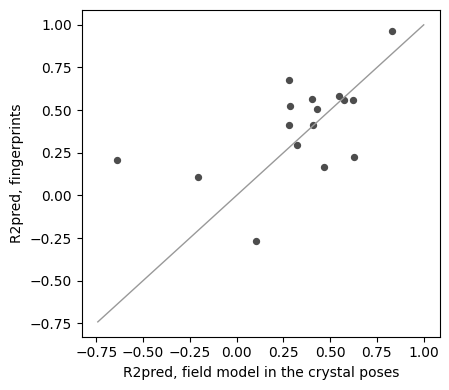

In [5]:
r2 = {m: [] for m in P.POSEFREE_MODELS}
for name in P.SETS:
    mols, names, y = P.load(name)
    tr, te = (np.asarray(v, int) for v in P.split(len(mols)))
    Ks = P.posefree_kernels(mols, names)
    mu = float(np.mean(y[tr]))
    for m in P.POSEFREE_MODELS:
        pred = P.ridge_predict(Ks[m], y, tr, te, P.LAM)
        r2[m].append(1.0 - np.sum((y[te] - pred) ** 2) / np.sum((y[te] - mu) ** 2))
flex = [r["methods"]["mcs+flex"]["r2_pred"] for r in rows_flex]
print("mean external R2pred over the 16 sets, the split of the pose runs:")
for m in P.POSEFREE_MODELS:
    print("   %-16s %+.3f   (best set %+.2f, worst %+.2f)" % (m, np.mean(r2[m]), np.max(r2[m]), np.min(r2[m])))
print("   %-16s %+.3f   (the flexible search, regenerated conformations)" % ("recovered poses", np.mean(flex)))

fig, ax = plt.subplots(figsize=(4.6, 4.0))
ax.scatter(r2["crystal poses"], r2["fingerprints"], color="0.3", s=18)
lim = [min(min(r2["crystal poses"]), min(r2["fingerprints"])) - 0.1, 1.0]
ax.plot(lim, lim, color="0.6", linewidth=1)
ax.set_xlabel("R2pred, field model in the crystal poses")
ax.set_ylabel("R2pred, fingerprints")
plt.tight_layout()
plt.show()

One split per set is noisy: six to thirteen held-out molecules per set. `run_poses.py --posefree`
repeats the three models over 20 random splits of every set, with the ridge of the protocol and with
the ridge chosen by five inner folds of the training part. The joint field kernel has a diagonal of
five and the other two of one, so one fixed ridge is not the same regularisation for all three.

In [6]:
pf = json.load(open(os.path.join(P.RESULTS, "posefree", "posefree.json")))
for ridge in pf["ridges"]:
    means = {m: np.mean([np.mean(s["r2"]["%s | %s" % (m, ridge)]) for s in pf["sets"].values()]) for m in pf["models"]}
    print("%s: mean R2pred over 16 sets x 20 splits: " % ridge + ", ".join("%s %+.3f" % (m, v) for m, v in means.items()))
print()
print("paired over the sets (bootstrap, 95 %):")
for key, v in pf["paired"].items():
    print("   %-52s %+.3f [%+.3f, %+.3f], ahead on %d of %d sets" % (key, v["diff"], v["low"], v["high"], v["sets_ahead"], v["n_sets"]))

ridge 0.1: mean R2pred over 16 sets x 20 splits: crystal poses +0.307, invariant +0.258, fingerprints +0.345
ridge chosen inside: mean R2pred over 16 sets x 20 splits: crystal poses +0.235, invariant +0.191, fingerprints +0.328

paired over the sets (bootstrap, 95 %):
   ridge 0.1: fingerprints - crystal poses              +0.038 [-0.042, +0.117], ahead on 9 of 16 sets
   ridge 0.1: invariant - crystal poses                 -0.049 [-0.122, +0.018], ahead on 7 of 16 sets
   ridge 0.1: fingerprints - invariant                  +0.087 [-0.003, +0.171], ahead on 12 of 16 sets
   ridge chosen inside: fingerprints - crystal poses    +0.094 [+0.013, +0.171], ahead on 10 of 16 sets
   ridge chosen inside: invariant - crystal poses       -0.043 [-0.151, +0.058], ahead on 9 of 16 sets
   ridge chosen inside: fingerprints - invariant        +0.137 [+0.050, +0.226], ahead on 13 of 16 sets


On the split of the pose runs the fingerprints reach a mean R2pred of +0.407, the field model in
the crystal poses +0.333, the invariant kernel +0.278, and the recovered poses +0.264. Over 20
splits per set the order of the fingerprints and the crystal poses holds with both ridges:

- with the ridge at 0.1, +0.345 against +0.307, a difference of +0.038 [-0.042, +0.117] that the
  interval does not separate from zero;
- with the ridge chosen inside, +0.328 against +0.235, a difference of +0.094 [+0.013, +0.171],
  ahead on 10 of the 16 sets.

So on these series a model that needs no pose predicts the held-out ligands at least as well as
the field model in the true poses. The recovered poses cannot be worth more than the true ones,
so on these sets they do not raise the prediction above a fingerprint. The invariant field kernel
is a little behind the crystal poses (-0.049 and -0.043, both intervals containing zero).

## What this shows and what it does not

**What it shows.**

- An alignment can be judged from outside the model: against crystal poses, with a floor and a
  ceiling, and by how near it comes and what the model then predicts.
- With the conformation known, the pose is nearly solved: 0.25 Å by the common substructure, 0.12
  Å by the field points with the variance search, which needs no substructure.
- With the conformation generated, a flexible search from five starting conformations recovers the
  pose to 0.86 Å, and what remains is mostly the conformation (a limit of 0.71 Å).
- A model that needs no pose is the reference a pose has to beat. On these sixteen congeneric
  series fingerprints predict the held-out ligands at least as well as the field model in the true
  poses.

**What it does not show.**

- That fields are useless. The FEP sets are congeneric series, where two-dimensional similarity
  is strong. A field model can still read things a fingerprint cannot, such as where in space a
  change acts (the co-field), and a series without a common scaffold is another question.
- Anything about poses in a protein. The protocol uses the frame of one crystal structure and never
  the receptor; the pocket methods of the benchmark did not help either.
- A result that does not depend on the ridge. With the fixed ridge of the protocol the difference
  between fingerprints and crystal poses is inside the noise; with a chosen ridge it is not.

Recovering a pose is a solved problem when the conformation is known and a nearly solved one when
it is not. Whether the pose is worth recovering is a question each series has to answer against a
model that needs none.